In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [2]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [3]:
categorical = df.select_dtypes(include='object').columns.tolist()
numerical = [c for c in df.select_dtypes(exclude='object').columns if c != 'converted']
print('categorical:', categorical)
print('numerical:', numerical)

# categorical -> 'NA', numerical -> 0.0
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
df.isnull().sum().sum()

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


np.int64(0)

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_full_train = df_full_train.converted.values

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

print(len(df_train), len(df_val), len(df_test))

3000 1000 1000


In [5]:
num_vars = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
res = {}
for col in num_vars:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    res[col] = round(auc, 4)
res = pd.Series(res).sort_values(ascending=False)
print(res)
print('\nHighest AUC:', res.idxmax())

lead_score                  0.7882
interaction_count           0.7649
number_of_courses_viewed    0.7230
annual_income               0.6082
dtype: float64

Highest AUC: lead_score


In [6]:
features = categorical + numerical

def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
print('Validation AUC:', round(roc_auc_score(y_val, y_pred), 3))

Validation AUC: 0.732


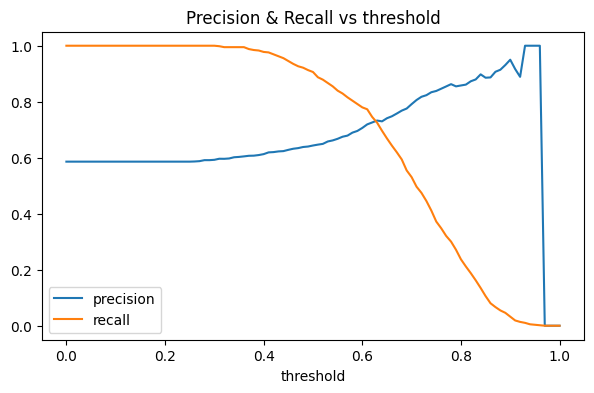

    threshold  precision    recall        f1      diff
63       0.63   0.732759  0.725256  0.728988  0.007503
62       0.62   0.725914  0.745734  0.735690  0.019820
64       0.64   0.729875  0.696246  0.712664  0.033629

Intersection threshold: 0.63


In [7]:
thresholds = np.arange(0.0, 1.01, 0.01)
rows = []
for t in thresholds:
    pred = (y_pred >= t)
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    rows.append((round(t, 2), p, r, f1))
scores = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])

plt.figure(figsize=(7, 4))
plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.title('Precision & Recall vs threshold')
plt.show()

valid = scores[(scores.precision > 0) | (scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
print(valid.sort_values('diff').head(3))
print('\nIntersection threshold:', valid.loc[valid['diff'].idxmin(), 'threshold'])

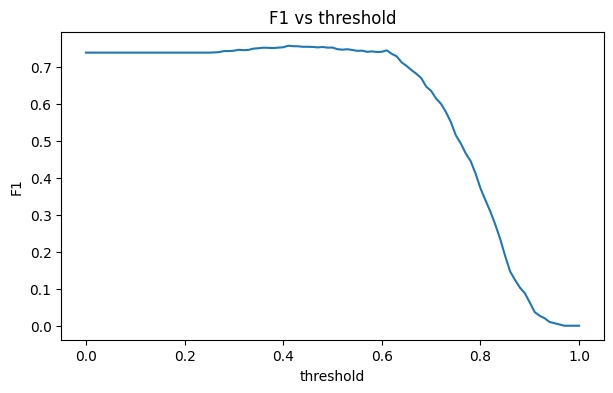

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

Threshold with max F1: 0.41


In [8]:
plt.figure(figsize=(7, 4))
plt.plot(scores.threshold, scores.f1)
plt.xlabel('threshold'); plt.ylabel('F1'); plt.title('F1 vs threshold')
plt.show()

best = scores.loc[scores.f1.idxmax()]
print(best)
print('\nThreshold with max F1:', best.threshold)

In [9]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
aucs = []
for tr_idx, va_idx in kfold.split(df_full_train):
    d_tr = df_full_train.iloc[tr_idx]
    d_va = df_full_train.iloc[va_idx]
    dv_, m_ = train(d_tr, d_tr.converted.values, C=1.0)
    p = predict(d_va, dv_, m_)
    aucs.append(roc_auc_score(d_va.converted.values, p))
print('fold AUCs:', np.round(aucs, 4))
print('Mean:', round(np.mean(aucs), 3), '| Std:', round(np.std(aucs), 3))

fold AUCs: [0.7306 0.7296 0.7363 0.7412 0.7209]
Mean: 0.732 | Std: 0.007


In [10]:
results = []
for C in [0.000001, 0.001, 1]:
    aucs = []
    for tr_idx, va_idx in kfold.split(df_full_train):
        d_tr = df_full_train.iloc[tr_idx]
        d_va = df_full_train.iloc[va_idx]
        dv_, m_ = train(d_tr, d_tr.converted.values, C=C)
        aucs.append(roc_auc_score(d_va.converted.values, predict(d_va, dv_, m_)))
    results.append((C, round(np.mean(aucs), 3), round(np.std(aucs), 3)))
res6 = pd.DataFrame(results, columns=['C', 'mean_auc', 'std_auc'])
print(res6)

# best mean; ties -> lowest std; still tied -> smallest C
best6 = res6.sort_values(['mean_auc', 'std_auc', 'C'], ascending=[False, True, True]).iloc[0]
print('\nBest C:', best6.C)

          C  mean_auc  std_auc
0  0.000001     0.617    0.019
1  0.001000     0.749    0.010
2  1.000000     0.732    0.007

Best C: 0.001
